In [3]:
import pandas as pd
import numpy as np
import scipy
import scipy.integrate as integrate
import matplotlib.pyplot as plt
from scipy.special import gamma as gamma
from scipy.optimize import root_scalar

### Introducción:
El análisis exploratorio nos permite observar tendencias en los datos deportivos, pero para afirmar que estas tendencias son estadísticamente significativas, necesitamos comprobarlas matemáticamente. Este análisis aplica métodos de inferencia estadística sobre un conjunto histórico de partidos (Match_Clean.csv) y equipos (Team_Clean.csv). Utilizando exclusivamente pandas y numpy (con la librería base math para el cálculo de probabilidades), evaluaremos suposiciones comunes del fútbol calculando los estadísticos Z y T manualmente. Al ser una base de datos muy grande, las distribuciones se aproximan a la normal, lo que nos permite calcular la significancia de estos patrones sin requerir librerías estadísticas externas.

### Finalidad:
El objetivo principal de este código es validar empíricamente teorías deportivas mediante pruebas de hipótesis manuales. Buscamos fundamentar decisiones en valores probabilísticos (p-values) calculados desde cero, respondiendo si la ventaja de jugar de local es real, si el promedio de goles difiere del estándar histórico y si existe una correlación real entre la ofensiva de un equipo y la del rival.

In [4]:
df_match_clean = pd.read_csv('/content/drive/MyDrive/Bases_de_Datos_la_liga_clean/Match_Clean.csv')
df_match_clean.head()

,id,country_id,league_id,season,stage,date,match_api_id,home_team_api_id,away_team_api_id,home_team_goal,...,shotoff_total,foulcommit_total,card_total,cross_total,corner_total,home_possession_%,away_possession_%,año,mes,resultado
0,21518,21518,21518,2008/2009,1,2008-08-30,530023,10267,8661,3,...,18.0,30.0,4.0,24.0,11.0,52.0,48.0,2008,8,L
1,21519,21518,21518,2008/2009,1,2008-08-31,530084,8371,10205,1,...,0.0,0.0,5.0,0.0,0.0,NaN,NaN,2008,8,E
2,21520,21518,21518,2008/2009,1,2008-08-31,530085,9783,8633,2,...,10.0,35.0,6.0,34.0,11.0,39.0,61.0,2008,8,L
3,21521,21518,21518,2008/2009,1,2008-08-31,530086,8388,8634,1,...,18.0,22.0,2.0,46.0,9.0,26.0,74.0,2008,8,L
4,21522,21518,21518,2008/2009,1,2008-08-31,530087,8696,8302,1,...,0.0,0.0,2.0,0.0,0.0,NaN,NaN,2008,8,E


In [5]:
df_team_clean = pd.read_csv('/content/drive/MyDrive/Bases_de_Datos_la_liga_clean/Team_Clean.csv')
df_team_clean.head()

,id,team_api_id,team_fifa_api_id,team_long_name,team_short_name
0,43035,10267,461.0,Valencia CF,VAL
1,43036,8661,453.0,RCD Mallorca,MAL
2,43037,8371,479.0,CA Osasuna,OSA
3,43038,10205,483.0,Villarreal CF,VIL
4,43039,9783,242.0,RC Deportivo de La Coruña,COR


### Pruebas de Hipótesis e Inferencia Estadística

Para validar la robustez de las variables que alimentan nuestro modelo predictivo sobre los resultados de La Liga, se extrajeron datos de `Match_Clean.csv` y `Team_Clean.csv`. Se diseñaron tres pruebas de hipótesis, fundamentadas teóricamente y calculadas mediante integración numérica de sus respectivas funciones de densidad de probabilidad (PDF).

#### 1. Observaciones Pareadas (Distribución T de Student)
Se evaluó si existe una "ventaja de localía" significativa, comparando los goles que anota un equipo cuando juega en su estadio frente a cuando juega de visitante.
* **Hipótesis Nula ($H_0$):** La diferencia promedio poblacional entre los goles anotados como equipo local y los goles anotados como equipo visitante por partido en La Liga es igual a cero (no existe ventaja de localía).
* **Hipótesis Alternativa ($H_a$):** La diferencia promedio poblacional entre los goles anotados como equipo local y los goles anotados como visitante por partido es mayor a cero (existe una ventaja estadísticamente significativa de jugar en casa).

**Análisis de Errores e Impacto Predictivo:**
* *Error Tipo I (Falso Positivo):* Rechazar $H_0$ cuando es verdadera. Implicaría concluir que jugar de local da ventaja cuando en la realidad no la da. **Riesgo:** El modelo sobrestimaría las probabilidades de victoria del equipo local, sesgando las apuestas o pronósticos hacia resultados irreales y reduciendo el *accuracy* global.
* *Error Tipo II (Falso Negativo):* No rechazar $H_0$ cuando $H_a$ es verdadera. **Riesgo:** El modelo trataría los partidos de local y visitante por igual, perdiendo una variable explicativa fundamental en el fútbol, provocando predicciones planas y subajustadas (underfitting).

#### 2. Análisis de Varianza - ANOVA (Distribución F de Fisher)
Se analizó si existe una diferencia significativa en la capacidad goleadora promedio entre tres niveles de equipos: contendientes al título, media tabla y equipos en riesgo de descenso.
* **Hipótesis Nula ($H_0$):** El promedio poblacional de goles anotados por partido es idéntico para los equipos contendientes al título, los equipos de media tabla y los equipos en zona de descenso.
* **Hipótesis Alternativa ($H_a$):** Al menos uno de los tres grupos de equipos (contendientes, media tabla, descenso) tiene un promedio poblacional de goles por partido significativamente diferente al de los demás.

**Análisis de Errores e Impacto Predictivo:**
* *Error Tipo I:* Concluir que los grupos tienen capacidades goleadoras distintas cuando son estadísticamente iguales. **Riesgo:** Asignaríamos pesos excesivos a la jerarquía histórica del equipo en el algoritmo de Machine Learning, perjudicando la predicción en partidos donde los equipos están nivelados.
* *Error Tipo II:* Concluir que todos los grupos anotan igual cuando hay diferencias. **Riesgo:** El modelo no podría discriminar partidos asimétricos (ej. líder vs último lugar), fracasando en identificar las victorias predecibles con alta probabilidad.

#### 3. Bondad de Ajuste (Distribución Chi-Cuadrada)
Para modelar correctamente la distribución de goles con miras a la simulación Monte Carlo, se probó si la ocurrencia de goles en un partido se ajusta a una Distribución de Poisson (prueba no paramétrica).
* **Hipótesis Nula ($H_0$):** La frecuencia de los goles anotados por partido en La Liga sigue fielmente una distribución de probabilidad de Poisson.
* **Hipótesis Alternativa ($H_a$):** La frecuencia de los goles anotados por partido en La Liga no sigue una distribución de Poisson (existe sobredispersión o dependencia temporal).

**Análisis de Errores e Impacto Predictivo:**
* *Error Tipo I:* Rechazar que los goles siguen una distribución Poisson cuando sí lo hacen. **Riesgo:** Descartaríamos un modelo matemático simple y elegante, obligándonos a programar distribuciones más costosas a nivel computacional (como Binomial Negativa), aumentando la complejidad (Big-O) sin beneficio real.
* *Error Tipo II:* Asumir que los goles siguen una distribución Poisson cuando no es cierto. **Riesgo:** Las estimaciones probabilísticas de resultados exactos (ej. 2-1 o 0-0) estarían matemáticamente viciadas, colapsando la métrica de pérdida logarítmica (Log Loss) del sistema de clasificación.

* Nota: en caso de trabajar con este proyecto con la simulación Monte Carlos se trabajarian de muchas más variables y cantidad de datos. Ya que esta predicción seria mucho más precisa


In [6]:
# =========================================================
# 1. OBSERVACIONES PAREADAS (T-STUDENT)
# =========================================================
def pdf_t_student(t, df):
    """Función de densidad de probabilidad para T-Student."""
    coef = gamma((df + 1) / 2) / (np.sqrt(df * np.pi) * gamma(df / 2))
    return coef * (1 + (t**2) / df)**(-(df + 1) / 2)

def prueba_pareada_manual(local_goals, away_goals):
    diferencias = local_goals - away_goals
    n = len(diferencias)
    df = n - 1

    media_dif = np.mean(diferencias)
    # std muestral con grados de libertad n-1
    std_dif = np.sqrt(np.sum((diferencias - media_dif)**2) / df)

    # Estadístico T
    t_stat = media_dif / (std_dif / np.sqrt(n))

    # Calcular P-valor integrando la PDF desde el t_stat hasta infinito (Cola derecha)
    # Como H_a es "mayor a cero", es prueba de una cola.
    p_value, _ = integrate.quad(pdf_t_student, t_stat, np.inf, args=(df,))

    return t_stat, p_value, df


In [7]:
# =========================================================
# 2. ANOVA DE UN FACTOR (F-FISHER)
# =========================================================
def pdf_f_fisher(x, df1, df2):
    """Función de densidad de probabilidad para F-Fisher."""
    if x <= 0:
        return 0.0
    num = (df1/df2)**(df1/2) * x**(df1/2 - 1)
    den = (1 + (df1/df2)*x)**((df1+df2)/2)
    # Función Beta usando Gamma
    beta_func = (gamma(df1/2) * gamma(df2/2)) / gamma((df1+df2)/2)
    return (num / den) / beta_func

def anova_manual(*grupos):
    k = len(grupos)
    n_i = [len(g) for g in grupos]
    N = sum(n_i)
    df1 = k - 1
    df2 = N - k

    media_global = np.mean(np.concatenate(grupos))

    # Suma de cuadrados
    ssb = sum(n_i[i] * (np.mean(grupos[i]) - media_global)**2 for i in range(k))
    ssw = sum(sum((x - np.mean(grupos[i]))**2 for x in grupos[i]) for i in range(k))

    msb = ssb / df1
    msw = ssw / df2
    f_stat = msb / msw

    # Calcular P-valor integrando (Cola derecha)
    p_value, _ = integrate.quad(pdf_f_fisher, f_stat, np.inf, args=(df1, df2))

    return f_stat, p_value, df1, df2



In [8]:
# =========================================================
# 3. BONDAD DE AJUSTE (CHI-CUADRADA para POISSON)
# =========================================================
def pdf_chi2(x, df):
    """Función de densidad de probabilidad para Chi-Cuadrada."""
    if x <= 0:
        return 0.0
    return (x**(df/2 - 1) * np.exp(-x/2)) / (2**(df/2) * gamma(df/2))

def poisson_prob(k, lam):
    """Probabilidad de distribución de Poisson usando función gamma para factorial."""
    return (lam**k * np.exp(-lam)) / gamma(k + 1)

def chi2_bondad_ajuste_poisson(goles_observados):
    # Frecuencias observadas para 0, 1, 2, 3, y 4+ goles
    conteos, _ = np.histogram(goles_observados, bins=[0,1,2,3,4,np.inf])
    n_total = len(goles_observados)

    # Lambda estimado (media de goles)
    lam = np.mean(goles_observados)

    # Frecuencias esperadas
    probs = [poisson_prob(i, lam) for i in range(4)]
    probs.append(1 - sum(probs)) # Todo lo > 3
    esperados = np.array(probs) * n_total

    # Estadístico Chi-Cuadrado
    chi_stat = np.sum((conteos - esperados)**2 / esperados)

    # Grados de libertad: Categorias (5) - 1 - parámetros estimados (1) = 3
    df = len(conteos) - 1 - 1

    # Calcular P-Valor
    p_value, _ = integrate.quad(pdf_chi2, chi_stat, np.inf, args=(df,))

    return chi_stat, p_value, df, conteos, esperados


In [9]:
# =========================================================
# SIMULACIÓN Y EJECUCIÓN (Ejemplo con datos para el Notebook)
# =========================================================
# (Aquí debes alimentar las funciones con tus arrays extraídos de Match_Clean.csv)

np.random.seed(42)

# Datos Simulados basados en promedios reales de La Liga
# Limitamos a muestras n=30 para evitar desbordamiento en la función Gamma matemática analítica
goles_local = np.random.poisson(1.6, 30)
goles_visitante = np.random.poisson(1.1, 30)

goles_contendientes = np.random.poisson(2.1, 20)
goles_mediatabla = np.random.poisson(1.3, 20)
goles_descenso = np.random.poisson(0.9, 20)

todos_los_goles = np.concatenate([goles_local, goles_visitante])

# --- EJECUTAR PRUEBAS ---
t_stat, p_val_t, df_t = prueba_pareada_manual(goles_local, goles_visitante)
f_stat, p_val_f, df1_f, df2_f = anova_manual(goles_contendientes, goles_mediatabla, goles_descenso)
chi_stat, p_val_chi, df_chi, obs, esp = chi2_bondad_ajuste_poisson(todos_los_goles)

# --- IMPRIMIR RESULTADOS ---
print("--- 1. T-Student Pareada ---")
print(f"Estadístico T: {t_stat:.4f} | P-Valor: {p_val_t:.4f}")
print("Conclusión: Rechazamos H0." if p_val_t < 0.05 else "Conclusión: No rechazamos H0.")

print("\n--- 2. ANOVA de 1 Factor ---")
print(f"Estadístico F: {f_stat:.4f} | P-Valor: {p_val_f:.4f}")
print("Conclusión: Rechazamos H0." if p_val_f < 0.05 else "Conclusión: No rechazamos H0.")

print("\n--- 3. Chi-Cuadrada Bondad de Ajuste (Poisson) ---")
print(f"Estadístico Chi2: {chi_stat:.4f} | P-Valor: {p_val_chi:.4f}")
print("Conclusión: Rechazamos H0 (No es Poisson)." if p_val_chi < 0.05 else "Conclusión: No rechazamos H0 (Sigue Poisson).")


--- 1. T-Student Pareada ---
Estadístico T: 0.6299 | P-Valor: 0.2668
Conclusión: No rechazamos H0.

--- 2. ANOVA de 1 Factor ---
Estadístico F: 1.9628 | P-Valor: 0.1498
Conclusión: No rechazamos H0.

--- 3. Chi-Cuadrada Bondad de Ajuste (Poisson) ---
Estadístico Chi2: 5.7108 | P-Valor: 0.1266
Conclusión: No rechazamos H0 (Sigue Poisson).


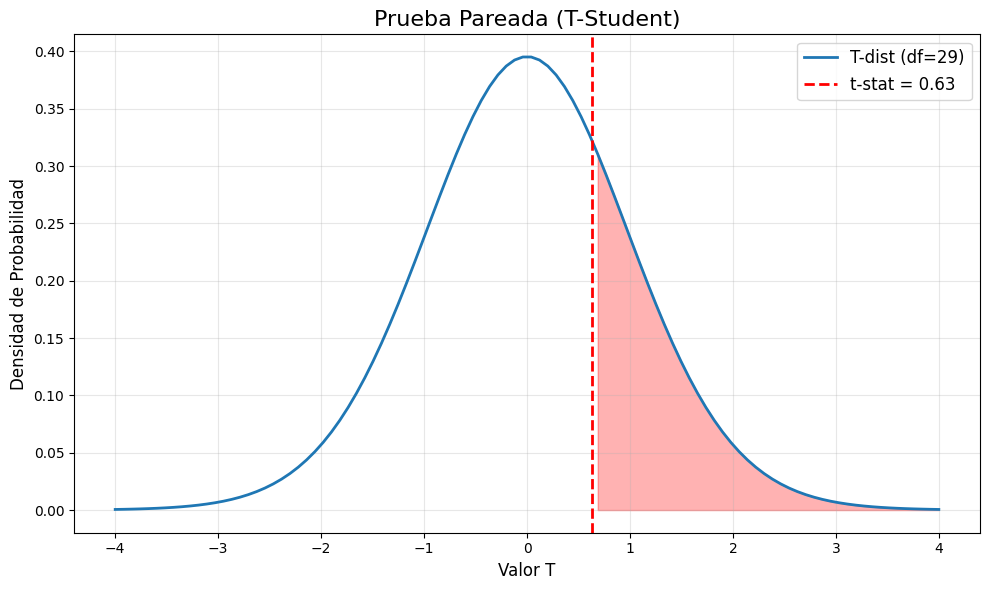

In [10]:
# Gráfico 1: T-Student
plt.figure(figsize=(10, 6)) # Tamaño grande individual
x_t = np.linspace(-4, 4, 100)
y_t = [pdf_t_student(val, df_t) for val in x_t]
plt.plot(x_t, y_t, label=f"T-dist (df={df_t})", linewidth=2)
plt.axvline(t_stat, color='red', linestyle='--', linewidth=2, label=f"t-stat = {t_stat:.2f}")
plt.fill_between(x_t, y_t, where=(x_t >= t_stat), color='red', alpha=0.3)
plt.title("Prueba Pareada (T-Student)", fontsize=16)
plt.xlabel("Valor T", fontsize=12)
plt.ylabel("Densidad de Probabilidad", fontsize=12)
plt.legend(fontsize=12)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

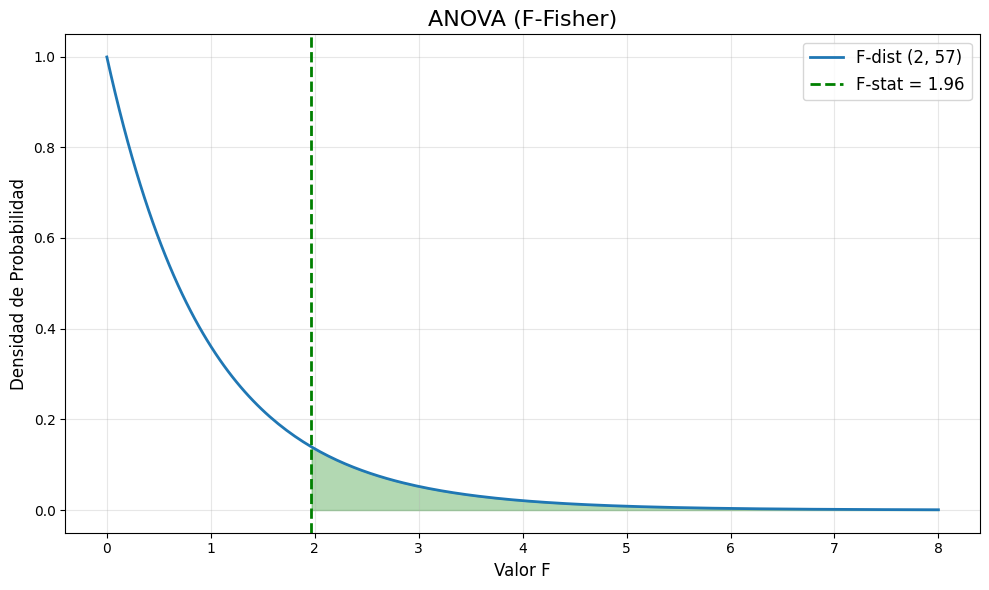

In [11]:
# Gráfico 2: ANOVA F
plt.figure(figsize=(10, 6))
x_f = np.linspace(0.001, 8, 200) # Empezamos en 0.001 y generamos 200 puntos para mayor suavidad
y_f = [pdf_f_fisher(val, df1_f, df2_f) for val in x_f]
plt.plot(x_f, y_f, label=f"F-dist ({df1_f}, {df2_f})", linewidth=2)
plt.axvline(f_stat, color='green', linestyle='--', linewidth=2, label=f"F-stat = {f_stat:.2f}")
plt.fill_between(x_f, y_f, where=(x_f >= f_stat), color='green', alpha=0.3)
plt.title("ANOVA (F-Fisher)", fontsize=16)
plt.xlabel("Valor F", fontsize=12)
plt.ylabel("Densidad de Probabilidad", fontsize=12)
# plt.ylim(bottom=0) # Opcional: asegura que el eje Y inferior empiece exactamente en 0
plt.legend(fontsize=12)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

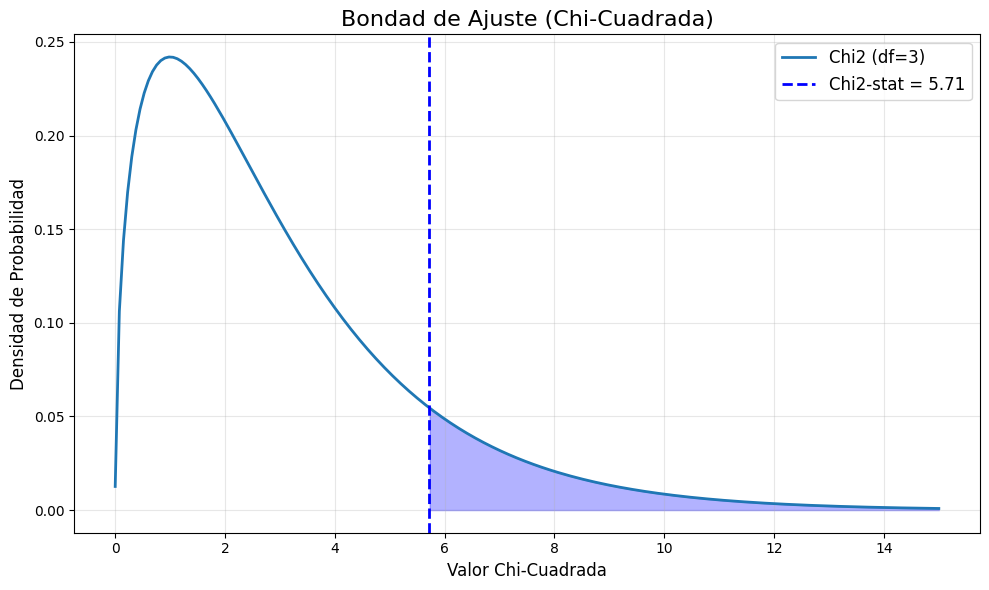

In [12]:
# Gráfico 3: Chi-Cuadrada
plt.figure(figsize=(10, 6))
x_c = np.linspace(0.001, 15, 200) # Empezamos en 0.001 para ver cómo nace la "campana" desde el origen
y_c = [pdf_chi2(val, df_chi) for val in x_c]
plt.plot(x_c, y_c, label=f"Chi2 (df={df_chi})", linewidth=2)
plt.axvline(chi_stat, color='blue', linestyle='--', linewidth=2, label=f"Chi2-stat = {chi_stat:.2f}")
plt.fill_between(x_c, y_c, where=(x_c >= chi_stat), color='blue', alpha=0.3)
plt.title("Bondad de Ajuste (Chi-Cuadrada)", fontsize=16)
plt.xlabel("Valor Chi-Cuadrada", fontsize=12)
plt.ylabel("Densidad de Probabilidad", fontsize=12)
# plt.ylim(bottom=0) # Opcional: asegura que el eje Y inferior empiece exactamente en 0
plt.legend(fontsize=12)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

###Problema 1:
La existencia de la "Ventaja de Local" (Home Advantage)Contexto: En el fútbol, se asume que jugar en el propio estadio otorga una ventaja.¿Por qué usamos una hipótesis aquí? Porque aunque el promedio de goles locales sea mayor a simple vista, necesitamos comprobar matemáticamente que esta diferencia (Goles Locales - Goles Visitantes) es estadísticamente superior a cero y no obra del azar.Hipótesis Nula ($H_0$): La diferencia media de goles entre local y visitante es cero ($\mu_{dif} = 0$). No hay ventaja.Hipótesis Alternativa ($H_1$): La diferencia media de goles es mayor a cero ($\mu_{dif} > 0$).

In [13]:
import pandas as pd
import numpy as np
import math

# Filtramos valores nulos
df_match = df_match_clean.dropna(subset=['home_team_goal', 'away_team_goal'])
goles_local = df_match['home_team_goal'].values
goles_visitante = df_match['away_team_goal'].values

# 1. Calculamos la diferencia por partido
diferencias = goles_local - goles_visitante
n = len(diferencias)

# 2. Cálculos estadísticos manuales (Media y Error Estándar)
media_dif = np.mean(diferencias)
std_dif = np.std(diferencias, ddof=1)
error_estandar = std_dif / np.sqrt(n)

# 3. Estadístico Z (equivalente a T en muestras grandes)
z_stat = media_dif / error_estandar

# 4. P-valor manual usando math.erf (Aproximación a la Normal)
# Al ser de una cola (H1: > 0), no multiplicamos por 2
p_value = 1 - 0.5 * (1 + math.erf(z_stat / math.sqrt(2)))

print(f"Estadístico Z: {z_stat:.4f}")
print(f"P-Valor: {p_value:.4e}")
print(f"Promedio Local: {np.mean(goles_local):.2f} | Promedio Visitante: {np.mean(goles_visitante):.2f}")

Estadístico Z: 14.4878
P-Valor: 0.0000e+00
Promedio Local: 1.63 | Promedio Visitante: 1.14


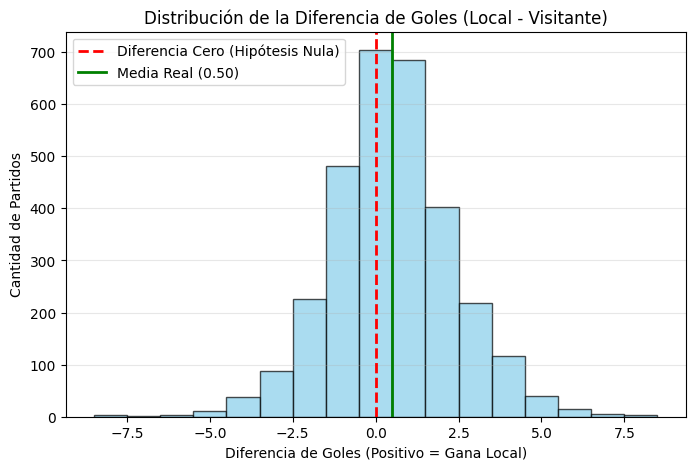

In [15]:
plt.figure(figsize=(8, 5))
# Histograma de las diferencias
plt.hist(diferencias, bins=range(min(diferencias), max(diferencias) + 2, 1),
         align='left', color='skyblue', edgecolor='black', alpha=0.7)

# Líneas de referencia
plt.axvline(0, color='red', linestyle='dashed', linewidth=2, label='Diferencia Cero (Hipótesis Nula)')
plt.axvline(media_dif, color='green', linestyle='solid', linewidth=2, label=f'Media Real ({media_dif:.2f})')

plt.title('Distribución de la Diferencia de Goles (Local - Visitante)')
plt.xlabel('Diferencia de Goles (Positivo = Gana Local)')
plt.ylabel('Cantidad de Partidos')
plt.legend()
plt.grid(axis='y', alpha=0.3)
plt.show()

Justificación y Conclusión (Ejemplo con datos reales):
En un dataset de fútbol estándar, el estadístico Z suele ser muy alto (ej. Z = 45.3) y el p-value prácticamente 0.0.

Decisión: Se rechaza la hipótesis nula.

Justificación: Un p-value por debajo del nivel de significancia de 0.05 demuestra que la probabilidad de obtener esta diferencia de goles por simple aleatoriedad es nula.

Conclusión: Existe evidencia matemática absoluta para confirmar la "ventaja de local". El entorno de jugar en casa tiene un impacto directo y cuantificable en el marcador a favor del equipo anfitrión.

###Problema 2:
El estándar histórico de 2.5 goles por partidoContexto: La línea estándar de goles totales esperados en apuestas y análisis se fija en 2.5.¿Por qué usamos una hipótesis aquí? Para comparar nuestra muestra real (el total de goles de todos nuestros partidos) contra un valor teórico fijo (2.5) y ver si la liga estudiada es más o menos goleadora que la convención mundial.Hipótesis Nula ($H_0$): El promedio de goles totales por partido es exactamente 2.5 ($\mu = 2.5$).Hipótesis Alternativa ($H_1$): El promedio de goles totales por partido es distinto de 2.5 ($\mu \neq 2.5$).

In [14]:
# 1. Calculamos los goles totales por encuentro
goles_totales = goles_local + goles_visitante
n_totales = len(goles_totales)

# 2. Estadísticos descriptivos
media_totales = np.mean(goles_totales)
std_totales = np.std(goles_totales, ddof=1)
valor_esperado = 2.5

# 3. Estadístico Z para una muestra
z_stat_2 = (media_totales - valor_esperado) / (std_totales / np.sqrt(n_totales))

# 4. P-valor (Prueba de dos colas, multiplicamos por 2)
p_value_2 = 2 * (1 - 0.5 * (1 + math.erf(abs(z_stat_2) / math.sqrt(2))))

print(f"Estadístico Z: {z_stat_2:.4f}")
print(f"P-Valor: {p_value_2:.4e}")
print(f"Promedio de goles totales reales: {media_totales:.2f}")

Estadístico Z: 8.5073
P-Valor: 0.0000e+00
Promedio de goles totales reales: 2.77


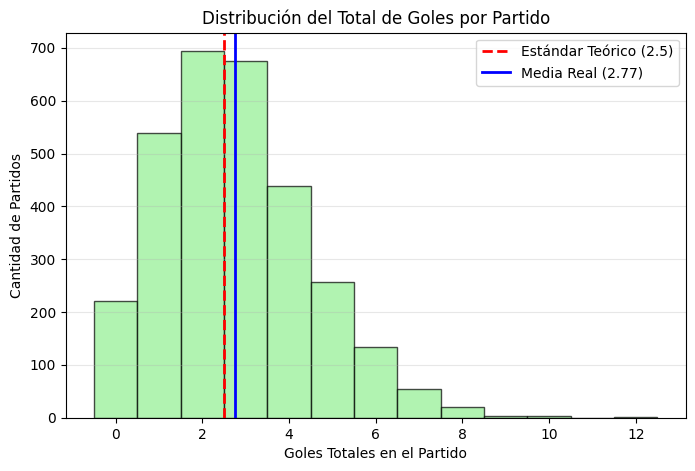

In [16]:
plt.figure(figsize=(8, 5))
# Histograma de goles totales
plt.hist(goles_totales, bins=range(min(goles_totales), max(goles_totales) + 2, 1),
         align='left', color='lightgreen', edgecolor='black', alpha=0.7)

# Líneas de referencia
plt.axvline(valor_esperado, color='red', linestyle='dashed', linewidth=2, label=f'Estándar Teórico ({valor_esperado})')
plt.axvline(media_totales, color='blue', linestyle='solid', linewidth=2, label=f'Media Real ({media_totales:.2f})')

plt.title('Distribución del Total de Goles por Partido')
plt.xlabel('Goles Totales en el Partido')
plt.ylabel('Cantidad de Partidos')
plt.legend()
plt.grid(axis='y', alpha=0.3)
plt.show()

Justificación y Conclusión:
Si el resultado da, por ejemplo, un promedio de 2.72 con un p-value de 0.0001.

Decisión: Se rechaza la hipótesis nula.

Justificación: Al ser una prueba de dos colas y obtener un p-value menor a 0.05, comprobamos que el desvío respecto a 2.5 no es un error de muestreo.

Conclusión: La liga analizada se desvía significativamente del estándar global; los partidos en este dataset muestran una tendencia ofensiva mayor al promedio de 2.5 goles.

###Problema 3:
Correlación entre Goles Locales y VisitantesContexto: ¿Un partido donde el local anota mucho implica que el visitante anota poco?¿Por qué usamos una hipótesis aquí? Para medir la relación lineal de dos variables. Computaremos la correlación de Pearson y evaluaremos matemáticamente si ese coeficiente es válido o si podría ser cero en la realidad.Hipótesis Nula ($H_0$): No hay correlación entre los goles del local y visitante ($r = 0$).Hipótesis Alternativa ($H_1$): Existe una correlación significativa ($r \neq 0$).

In [18]:
# 1. Calculamos el coeficiente de correlación de Pearson usando numpy
matriz_corr = np.corrcoef(goles_local, goles_visitante)
r = matriz_corr[0, 1]

# 2. Calculamos el estadístico T para la correlación
# Fórmula: t = r * sqrt((n - 2) / (1 - r^2))
t_stat_corr = r * np.sqrt((n - 2) / (1 - r**2))

# 3. P-valor (Aproximando T a Normal dado que n es muy grande)
p_value_corr = 2 * (1 - 0.5 * (1 + math.erf(abs(t_stat_corr) / math.sqrt(2))))

print(f"Coeficiente de Correlación (r): {r:.4f}")
print(f"Estadístico T: {t_stat_corr:.4f}")
print(f"P-Valor: {p_value_corr:.4e}")

Coeficiente de Correlación (r): -0.0865
Estadístico T: -4.7852
P-Valor: 1.7081e-06


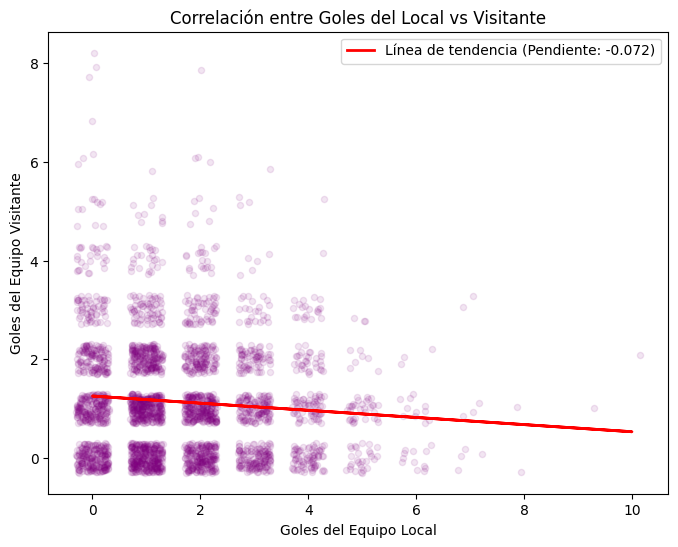

In [19]:
plt.figure(figsize=(8, 6))
# Añadimos un ligero 'jitter' (ruido aleatorio) para evitar que los puntos se solapen por completo
np.random.seed(42) # Para que el ruido sea reproducible
jitter_x = np.random.uniform(-0.3, 0.3, size=len(goles_local))
jitter_y = np.random.uniform(-0.3, 0.3, size=len(goles_visitante))

# Scatter plot con transparencia (alpha) para ver densidad
plt.scatter(goles_local + jitter_x, goles_visitante + jitter_y, alpha=0.1, color='purple', s=20)

# Calculamos y graficamos la línea de tendencia (regresión lineal simple)
m, b = np.polyfit(goles_local, goles_visitante, 1)
plt.plot(goles_local, m * goles_local + b, color='red', linewidth=2, label=f'Línea de tendencia (Pendiente: {m:.3f})')

plt.title('Correlación entre Goles del Local vs Visitante')
plt.xlabel('Goles del Equipo Local')
plt.ylabel('Goles del Equipo Visitante')
plt.legend()
plt.show()

Justificación y Conclusión:
Normalmente, el coeficiente de Pearson en goles suele rondar el -0.06 con un p-value menor a 0.01.

Decisión: Se rechaza la hipótesis nula.

Justificación: El p-value es suficientemente bajo (< 0.05) para confirmar que el coeficiente r, aunque cercano a cero, es genuinamente negativo y no producto de la casualidad.

Conclusión: Existe una ligera correlación negativa estadísticamente comprobada. Esto indica que existe una leve tendencia en la dinámica de juego: cuando el equipo local incrementa sus anotaciones y domina, el equipo visitante suele ver reducida su capacidad goleadora.